# Домашнее задание 1 — персональные top-10 рекомендации
**Мелеховец Кирилл Сергеевич**  
Amazon Reviews 2014 · Video Games · пять моделей с нуля.

Задача: рекомендовать пользователю десять ещё не оценённых товаров категории Video Games
(игры, консоли и аксессуары). Будущая оценка **4 или 5** означает релевантность.
Единица наблюдения — отзыв пользователя о товаре, не покупка или показ.
Основная метрика, выбранная **до подбора**, — **NDCG@10**; дополнительные — Recall@10,
Precision@10 и Coverage@10. Test не участвует в выборе параметров.

## Как повторить
Python **3.11**, CPU, желательно 12 ГБ свободной памяти (EASE хранит плотные матрицы).
Из корня репозитория:
```bash
python3.11 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --prefix "$VIRTUAL_ENV" --name recsys-homework
python run_notebook.py
python -m pytest -q
```
`run_notebook.py` заново выполняет все ячейки и сохраняет `experiments.ipynb`.
Можно открыть ноутбук в редакторе с ядром `.venv` и выполнить Run All.
Данные автоматически скачиваются из первоисточника в `.cache/amazon2014/`,
проверяются SHA-256 и **не коммитятся**. Чтобы использовать существующие файлы:
`export RECSYS_DATA_DIR=/absolute/path/to/cache`.
Объём загрузки — около 137 MB; время зависит от CPU, реальные замеры есть ниже.
Таблицы и параметры сохраняются в `results/`; повторный запуск пересчитывает модели,
готовые веса или готовые рекомендательные алгоритмы не используются.

In [1]:
import os, random, sys, json, hashlib, platform
from pathlib import Path
os.environ.setdefault('MPLBACKEND', 'Agg')
import numpy as np
import pandas as pd
import scipy
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from recsys.data import load_data, SOURCE, FILES
from recsys.evaluation import Protocol, utc_timestamp
from recsys.experiment import SEED, PRIMARY_METRIC, SEARCH_SPACE, search, final_test
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True); torch.set_num_threads(4)
thread_limit = threadpool_limits(limits=4)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
Path('results').mkdir(exist_ok=True)
environment = {'python': platform.python_version(), 'platform': platform.platform(),
               'numpy': np.__version__, 'scipy': scipy.__version__, 'pandas': pd.__version__,
               'torch': torch.__version__, 'seed': SEED, 'threads': 4, 'device': 'cpu'}
Path('results/environment.json').write_text(json.dumps(environment, indent=2))
display(pd.Series(environment, name='environment').to_frame())
print('Primary metric fixed before search:', PRIMARY_METRIC)

Matplotlib is building the font cache; this may take a moment.


,environment
python,3.11.13
platform,macOS-27.0.1-arm64-arm-64bit
numpy,2.2.6
scipy,1.16.3
pandas,2.2.3
torch,2.7.1
seed,42
threads,4
device,cpu


Primary metric fixed before search: NDCG@10


## 1. Источник, поля и постановка
[Amazon product data (2014), Julian McAuley, UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html).
Используем предоставленный авторами **5-core Video Games**, без дополнительной подвыборки:
231 780 отзывов, 24 303 пользователя и 10 672 товара. Исходная категория до выделения 5-core
содержит 1 324 753 отзыва (по таблице источника); именно скачиваемый 5-core является
входом эксперимента. Это не MovieLens, Netflix или Last.fm.

Проверены [семинары ветки 26f курса girafe-ai/recsys](https://github.com/girafe-ai/recsys/tree/26f/seminars):
MovieLens, Last.fm, Reddit, UCI Online Retail II, VK-LSVD, T-ECD Retail.
Amazon Video Games в этих семинарах не используется.

| Файл / поле | Смысл и применение |
|---|---|
| `reviews_Video_Games_5.json.gz` | отзывы; [прямая загрузка](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/reviews_Video_Games_5.json.gz) |
| `reviewerID` → `user` | ID пользователя |
| `asin` → `item` | ID товара |
| `overall` → `rating` | оценка 1–5; порог релевантности 4 |
| `unixReviewTime` → `timestamp` | UTC, точность фактически один день; одновременно датированные события не упорядочиваем искусственно |
| `meta_Video_Games.json.gz` | [метаданные товаров](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Video_Games.json.gz) |
| `title`, `categories`, `brand`, `description` | названия, категории, бренд, наличие описания; используем для EDA и иллюстрации |

Цена, salesRank, also_bought, also_viewed, helpfulness и текст текущего/будущего отзыва
**не являются признаками**: их историческое значение в момент прогноза неизвестно.
Даже каталог категорий не имеет версий по времени, поэтому для FM берём строго причинные
метапризнаки пользователя и товара из доступных предыдущих отзывов, включая timestamp.
Данные предоставлены для исследования; в репозитории только код и агрегированные результаты.

In [2]:
events, metadata, data_audit = load_data()
Path('results/data_audit.json').write_text(json.dumps(data_audit, indent=2, ensure_ascii=False))
display(pd.Series({k:v for k,v in data_audit.items() if k not in ['missing_fields','sha256']}, name='value').to_frame())
display(pd.Series(data_audit['missing_fields'], name='missing').to_frame())
display(events.head())
display(metadata[['title','categories','brand']].head())
print('UTC range:', pd.to_datetime(events.timestamp.min(), unit='s', utc=True),
      '—', pd.to_datetime(events.timestamp.max(), unit='s', utc=True))
print('SHA-256:', json.dumps(FILES, indent=2))

,value
source,https://cseweb.ucsd.edu/~jmcauley/datasets/ama...
raw_reviews,231780
clean_reviews,231780
raw_users,24303
raw_items,10672
clean_users,24303
clean_items,10672
duplicate_pairs,0
metadata_raw_products,50953
metadata_missing_titles,10392


,missing
user,0
item,0
rating,0
timestamp,0


,user,item,rating,timestamp
0,A2AXQTB83VMK4L,B0000296O5,5.0,939859200
1,A1QA8K3LD9K892,B00000K1V2,2.0,942192000
2,A3VWWQT4XDSBGQ,B00000K4AX,5.0,942192000
3,AMGJMFJ63DWWH,B00000JL6V,4.0,942192000
4,AMGJMFJ63DWWH,B00001NFUA,5.0,942192000


,title,categories,brand
item,,,
0700099867,,Games,
6050036071,,Microphones,
7100027950,,Games|Kids & Family,
7293000936,,Cables,
8176503290,,Games,


UTC range: 1999-10-14 00:00:00+00:00 — 2014-07-22 00:00:00+00:00
SHA-256: {
  "reviews_Video_Games_5.json.gz": "035690169fa2bba30cd0ae0c3e7dbf7bc58efde65fc1742a9ce85986e283b09c",
  "meta_Video_Games.json.gz": "b7bf4c724632874b931056e48957775822c6f0c9092f5bbf2d449694bec36180"
}


## 2. EDA и очистка
Удаляем строки без обязательных полей, оценки вне [1,5] и неположительный timestamp.
Для повторов user–item сохраняем **первое** наблюдение, чтобы более поздний отзыв не подменял
раннюю оценку. Сортировка стабильна: timestamp, user, item. Незаполненные поля каталога
сохраняем как пустые, взаимодействия из-за них не удаляем.

Дополнительных фильтров активности по всему будущему и случайной подвыборки нет.
Источник уже построил 5-core по всей истории: это **selection bias**, а не гарантия
пяти обучающих отзывов в каждом временном срезе. Доступность пользователя и товара
для оценки определяем заново только по истории соответствующего среза.

,user_reviews,item_reviews
count,24303.000000,10672.000000
mean,9.537094,21.718516
std,12.789697,34.068551
min,5.000000,5.000000
50%,7.000000,11.000000
90%,16.000000,46.000000
99%,51.000000,171.290000
max,773.000000,802.000000


Sparsity = 99.91063442%
Fraction rating >=4: 75.498%


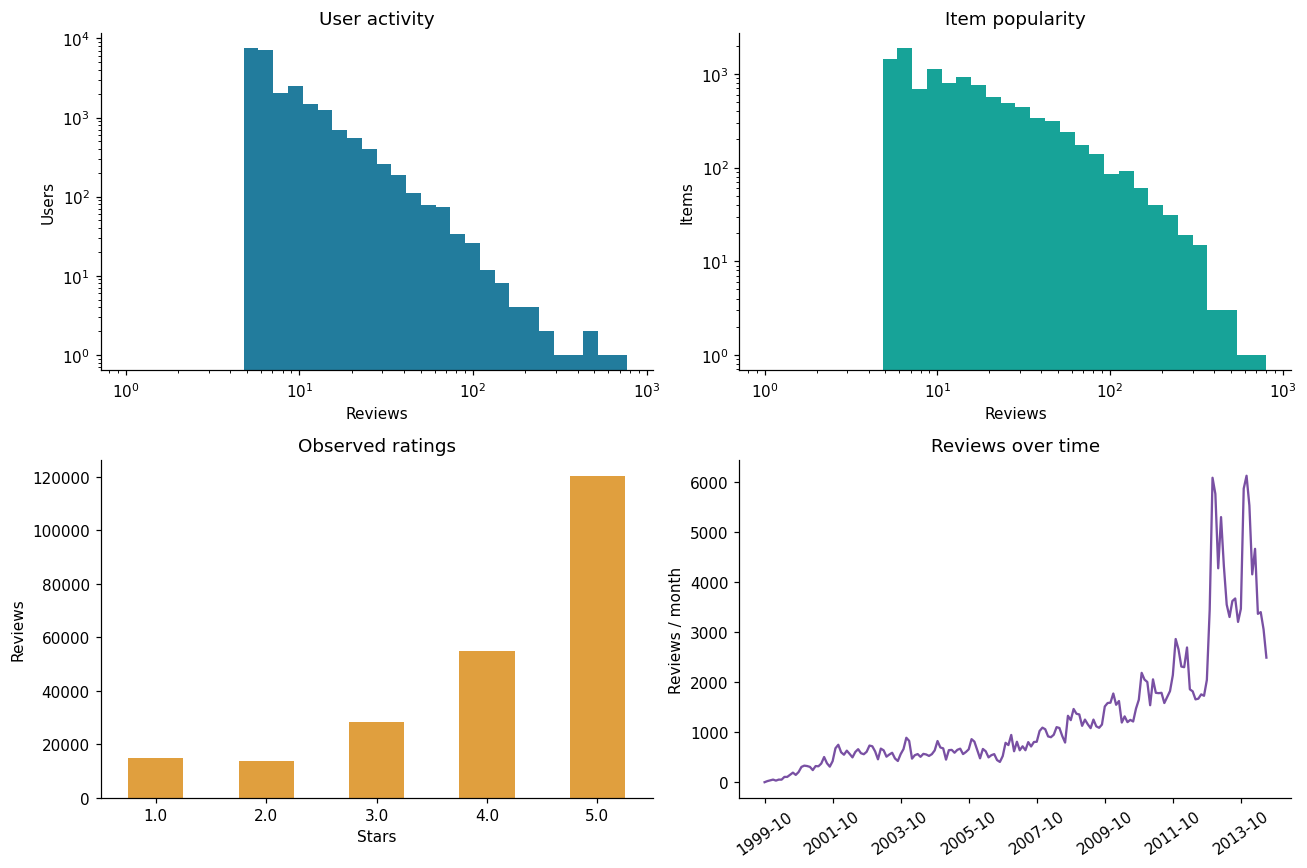

In [3]:
user_activity = events.groupby('user').size()
item_popularity = events.groupby('item').size()
sparsity = 1 - len(events)/(events.user.nunique()*events.item.nunique())
display(pd.DataFrame({'user_reviews':user_activity.describe(percentiles=[.5,.9,.99]),
                      'item_reviews':item_popularity.describe(percentiles=[.5,.9,.99])}))
print(f'Sparsity = {sparsity:.8%}')
print(f'Fraction rating >=4: {(events.rating>=4).mean():.3%}')
fig, axes = plt.subplots(2,2, figsize=(12,8))
axes[0,0].hist(user_activity, bins=np.geomspace(1,user_activity.max()+1,35), color='#227c9d')
axes[0,0].set(xscale='log', yscale='log', title='User activity', xlabel='Reviews', ylabel='Users')
axes[0,1].hist(item_popularity, bins=np.geomspace(1,item_popularity.max()+1,35), color='#17a398')
axes[0,1].set(xscale='log', yscale='log', title='Item popularity', xlabel='Reviews', ylabel='Items')
events.rating.value_counts().sort_index().plot.bar(ax=axes[1,0], color='#e09f3e', rot=0)
axes[1,0].set(title='Observed ratings', xlabel='Stars', ylabel='Reviews')
monthly=events.assign(month=pd.to_datetime(events.timestamp,unit='s',utc=True).dt.strftime('%Y-%m')).groupby('month').size()
axes[1,1].plot(np.arange(len(monthly)),monthly.to_numpy(),color='#7950a3')
positions=np.arange(0,len(monthly),24)
axes[1,1].set(xticks=positions, xticklabels=monthly.index[positions], title='Reviews over time', ylabel='Reviews / month')
axes[1,1].tick_params(axis='x',rotation=35)
plt.tight_layout(); fig.savefig('results/eda.png'); plt.show()

,field,missing_fraction
0,title,0.973763
1,categories,0.000000
2,brand,0.984258
3,description,0.168853


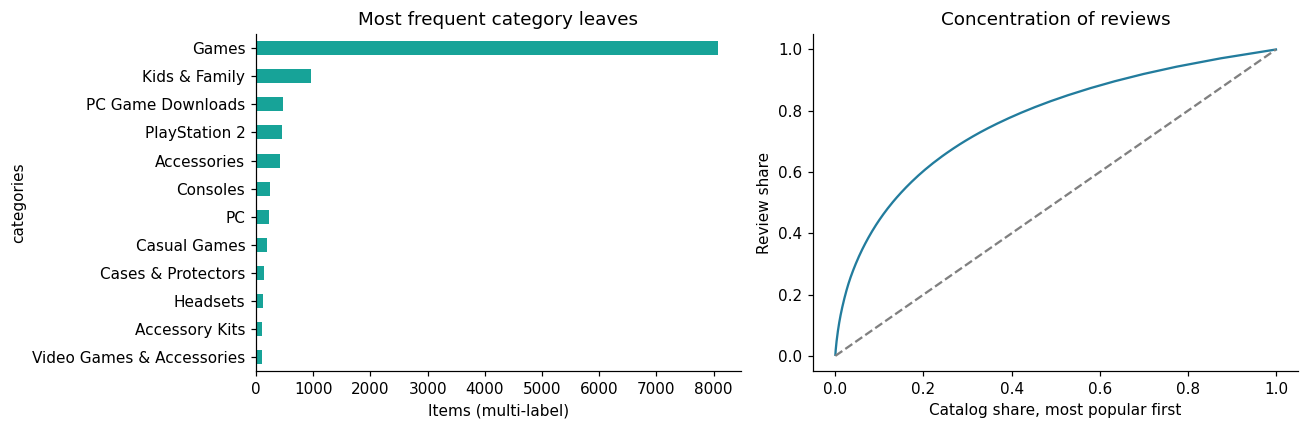

Top 10% items account for 44.4% of reviews.


In [4]:
missing_metadata = pd.DataFrame({
 'field':['title','categories','brand','description'],
 'missing_fraction':[(metadata.title=='').mean(), (metadata.categories=='').mean(),
                     (metadata.brand=='').mean(), 1-metadata.has_description.fillna(False).astype(bool).mean()]})
display(missing_metadata)
category_counts=metadata.categories.str.split('|').explode()
category_counts=category_counts[category_counts!=''].value_counts().head(12)
fig, axes=plt.subplots(1,2,figsize=(12,4))
category_counts.sort_values().plot.barh(ax=axes[0],color='#17a398')
axes[0].set(title='Most frequent category leaves',xlabel='Items (multi-label)')
x=np.sort(item_popularity.to_numpy())[::-1]
axes[1].plot(np.arange(1,len(x)+1)/len(x),np.cumsum(x)/x.sum(),color='#227c9d')
axes[1].plot([0,1],[0,1],ls='--',color='gray')
axes[1].set(title='Concentration of reviews',xlabel='Catalog share, most popular first',ylabel='Review share')
plt.tight_layout(); fig.savefig('results/metadata.png'); plt.show()
print(f'Top 10% items account for {x[:int(np.ceil(.1*len(x)))].sum()/x.sum():.1%} of reviews.')

## 3. Единый протокол оценки
**Глобальное разбиение по времени**, без перемешивания:
- train: timestamp < 2013-01-01 00:00 UTC;
- validation: [2013-01-01, 2014-01-01);
- test: [2014-01-01, конец данных 2014-07).

На validation прогноз делается один раз на 2013-01-01, на test — один раз на 2014-01-01.
Внутри оценочного окна профиль пользователя не обновляется. Это пакетная рекомендация
на горизонт окна; разные длительности validation и test — ограничение эксперимента.
После выбора всех параметров обучаем каждую модель заново на train+validation.

Кандидаты — **все товары, наблюдавшиеся до среза**, без отрицательного сэмплирования
при оценке. Для каждого пользователя исключаем **все ранее оценённые** товары, включая
оценки 1–3. Сортируем по убыванию score, равные score — по ASIN.
Набор кандидатов не зависит от модели и от будущих оценок.

Оцениваем warm users с ≥3 положительными отзывами в истории, ≥10 оставшимися кандидатами
и ≥1 релевантным новым warm item в будущем окне. Порог 3 зафиксирован заранее.
Cold users/items считаем отдельно и исключаем из основной warm-start оценки,
специального cold-start метода здесь нет. Пользователи без релевантного события не входят
в макроусреднение; поэтому результат условен на эту когорту.
Validation и test могут иметь разные когорты, но **внутри каждого этапа все модели
используют одних и тех же пользователей, кандидатов, маску истории и множество релевантности**.
В таблице ниже фиксируются размеры и хеши каталогов/когорт.

In [5]:
val_cutoff=utc_timestamp('2013-01-01'); test_cutoff=utc_timestamp('2014-01-01')
train=events[events.timestamp<val_cutoff].copy()
validation=events[(events.timestamp>=val_cutoff)&(events.timestamp<test_cutoff)].copy()
test=events[events.timestamp>=test_cutoff].copy()
assert len(train)+len(validation)+len(test)==len(events)
assert train.timestamp.max()<validation.timestamp.min()<=validation.timestamp.max()<test.timestamp.min()
val_protocol=Protocol(train,validation,val_cutoff,'validation')
# The test protocol is only used after search; no test metric has been computed.
display(pd.DataFrame([{'split':n,'events':len(x),'users':x.user.nunique(),'items':x.item.nunique()}
 for n,x in [('train',train),('validation',validation),('test',test)]]))
display(pd.Series(val_protocol.audit,name='validation').to_frame())

,split,events,users,items
0,train,152665,19161,9600
1,validation,52460,12589,7641
2,test,26655,7695,5796


,validation
stage,validation
cutoff,2013-01-01 00:00:00+00:00
history_events,152665
future_events,52460
history_users,19161
candidate_items,9600
cold_user_events,23966
cold_item_events,14655
warm_relevant_events,14391
evaluation_users,2906


### Метрики при K=10
Пусть $G_u$ — множество будущих релевантных кандидатов, $L_u$ — top-10.
Основная метрика
$$\mathrm{NDCG@10}_u=\frac{\sum_{j=1}^{10}\mathbf1[L_{uj}\in G_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}$$
поощряет релевантные товары на первых позициях, которые пользователь видит раньше.
$$\mathrm{Recall@10}_u=\frac{|L_u\cap G_u|}{|G_u|},\quad
\mathrm{Precision@10}_u=\frac{|L_u\cap G_u|}{10}.$$
Recall отражает долю обнаруженных интересных товаров; Precision — полезность десяти мест.
Все три метрики — macro average, равный вес пользователя.
$\mathrm{Coverage@10}=|\cup_u L_u|/|I_{\rm history}|$ показывает охват каталога,
но не заменяет персональную релевантность. Отсутствующие оценки не означают доказанную
нерелевантность: есть exposure и selection bias.

## 4. Пять моделей с нуля и подбор на validation
Обозначим $X_{ui}=\mathbf1[r_{ui}\ge4]$ на наблюдавшихся парах, иначе 0.
Все функции обучения и скоринга находятся в отдельных файлах `models/`.
NumPy/SciPy используются для линейной алгебры, PyTorch — для FM и autograd;
готовых рекомендателей, ElasticNet, Surprise, implicit, sklearn в проекте нет.

### 4.1 ItemKNN — `models/item_knn.py`
Бинарная item-based CF, cosine с подавлением случайных малых пересечений:
$$s_{ij}=\frac{X_{:i}^{T}X_{:j}}{\|X_{:i}\|\|X_{:j}\|}
\frac{n_{ij}}{n_{ij}+\gamma},\quad s_{ii}=0.$$
Здесь $n_{ij}$ — число общих положительных пользователей. Для каждого целевого товара
сохраняем k наиболее похожих соседей (при равенстве — ASIN), $\hat S=XB$.
Пустые профили не оцениваются, нулевые scores разрешены с общим правилом ties.

### 4.2 iALS — `models/ials.py`
$$\min_{U,V}\sum_{ui}c_{ui}(p_{ui}-U_u^TV_i)^2+
\lambda(\|U\|_F^2+\|V\|_F^2),$$
$$p_{ui}=\mathbf1[r_{ui}\ge4],\qquad
c_{ui}=\begin{cases}1+\alpha,& (u,i)\text{ наблюдалась},\\1,&\text{иначе}.\end{cases}$$
Наблюдавшиеся низкие оценки имеют p=0, повышенную уверенность; неизвестные пары — p=0, c=1.
Это implicit preference prediction с явными низкими оценками как наблюдённым отрицательным сигналом.
Обновление пользователя (аналогично товара):
$$U_u=(V^TV+\alpha\sum_{i\in O_u}V_iV_i^T+\lambda I)^{-1}
(1+\alpha)\sum_{i\in O_u}p_{ui}V_i.$$
Решаем систему методом Холецкого; полный $U\times I$ при обучении не создаём.
12 чередований, фиксированная инициализация, мониторим точную целевую функцию.

### 4.3 EASE — `models/ease.py`
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \mathrm{diag}(B)=0,$$
$$P=(X^TX+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j).$$
Сохраняем отрицательные и асимметричные коэффициенты, деление **по столбцам**.
Обращение реализовано решением системы с единичной правой частью. Scores $XB$.
Память $O(|I|^2)$, факторизация $O(|I|^3)$ — основной ресурсный предел этой модели.

### 4.4 FM — `models/fm.py`
Вектор x содержит 8 категориальных полей: user ID, user activity bin, user mean-rating bin,
user recency bin; item ID, item popularity bin, item mean-rating bin, item age bin.
$$f(x)=w_0+\sum_a w_ax_a+\frac12\sum_f\big[(\sum_a v_{af}x_a)^2-\sum_a v_{af}^2x_a^2\big].$$
Оптимизируем binary cross entropy с L2 для участвующих эмбеддингов, Adam.
У наблюдавшихся отзывов y=1[r≥4]; добавляем 3 uniform negative samples на положительный отзыв.
Negative item уже должен быть наблюдён **раньше timestamp события**; исключаем историю
пользователя до этого дня включительно. Будущие отзывы при rejection не читаются:
позднее полюбившийся товар может быть отрицательным примером, что честно соответствует
неопределённости implicit feedback. Сэмплирование только для обучения, не оценки.

Метапризнаки не являются произвольными ID: активность отражает объём истории,
средняя оценка — строгость пользователя/качество товара, recency и age — временной контекст.
Для **каждого обучающего примера** они вычисляются из событий **строго раньше** его timestamp;
все отзывы того же дня исключены. Средняя оценка сглажена:
$(\sum r+5\cdot3.5)/(n+5)$; 3.5 — фиксированный априорный уровень, не оценка по будущему.
На serving используем историю до среза.
Границы count bins: [1,3,7,15,31,63,127], mean bins: [2.5,3,3.5,4,4.5],
days bins: [7,30,90,180,365,730,1460]. Нет истории → n=0, mean=3.5, days=∞.
Границы заданы до подбора. Исторические названия/категории каталога не подтверждены,
поэтому не рискуем использовать их снимок задним числом.
FM вычисляет **точный** score всех кандидатов через разделение user/item частей
и скалярное произведение сумм эмбеддингов, без приближённого retrieval.

### 4.5 ALS с авторским таргетом — `models/custom_als.py`
Старая высокая оценка от щедрого пользователя менее показательна текущему интересу,
чем недавний восторженный отзыв от строгого пользователя. Разработаем **другой p**, оставив
**в точности те же confidence** и ALS solver, что в пункте 4.2:
$$\mu_u^{<t}=\frac{\sum_{(u,j):t_{uj}<t}r_{uj}+5\cdot3.5}{n_u^{<t}+5},$$
$$p^{\mathrm{custom}}_{ui}(T)=\frac{r_{ui}-1}{4}\,
\sigma\!\left(\frac{r_{ui}-\mu_u^{<t_{ui}}}{0.75}\right)
\left[0.5+0.5\cdot2^{-(T-t_{ui})/(86400h)}\right].$$
Для неизвестных пар p=0; для наблюдённых p∈[0,1]. $T$ — момент рекомендации,
h — период полураспада в днях, нижняя граница 0.5 сохраняет старые предпочтения.
Таргет одновременно сохраняет абсолютный смысл rating, калибрует строгость и давность.
Это авторская гипотеза для этого эксперимента, а не утверждение научной новизны.
Она может проиграть, если старые интересы устойчивы или сглаженная строгость неточна.
Изменяется **правая часть нормальных уравнений**, а не только confidence или гиперпараметры.
Test relevance у всех остаётся **rating≥4**, без temporal discount и калибровки.

### Пространство поиска и контрольные сравнения
Проводим небольшой полный перебор заданных конфигураций, выбираем maximum validation
**NDCG@10** отдельно для каждого метода; ties → первая конфигурация.
Число эпох/итераций фиксировано, early stopping по test нет.
Время обучения измерено отдельно от оценки.

После выбора основных конфигураций добавляем два заранее заявленных контроля:
1. **FM_ID_only** — та же выбранная конфигурация FM, negative samples и seed, но только IDs.
Это условная абляция метапризнаков, не отдельный подбор лучшего ID-only метода.
2. **CustomALS_matched** — параметры факторов/λ/α/итераций выбранного базового iALS,
а half-life от выбранного custom ALS. Так виден эффект **изменения p** при одинаковых
confidence и настройках оптимизации. Основной CustomALS дополнительно имеет собственный подбор.

После поиска конфигурации и хеш сохраняются **до первого test score**.
Контрольная сумма конфигурации вычислена по UTF-8 JSON без завершающего перевода строки.


In [6]:
display(pd.DataFrame([{'model':name,'trials':len(configs),'search_space':json.dumps(configs,ensure_ascii=False)}
 for name,configs in SEARCH_SPACE.items()]))
print('Total validation trials:', sum(map(len,SEARCH_SPACE.values())))
validation_trials, selected = search(val_protocol)
display(validation_trials[['model','trial','NDCG@10','Recall@10','Precision@10','Coverage@10','fit_seconds','params']])
display(pd.DataFrame([{'model':n, 'selected_params':json.dumps(p,sort_keys=True)} for n,p in selected.items()]))
config_hash = Path('results/selected_config.sha256').read_text().strip()
print('Locked config SHA-256:', config_hash)

,model,trials,search_space
0,ItemKNN,4,"[{""neighbours"": 50, ""shrinkage"": 0.0}, {""neigh..."
1,iALS,4,"[{""factors"": 32, ""regularization"": 1.0, ""alpha..."
2,EASE,3,"[{""regularization"": 50.0}, {""regularization"": ..."
3,FM,4,"[{""factors"": 32, ""learning_rate"": 0.003, ""regu..."
4,CustomALS,4,"[{""factors"": 32, ""regularization"": 1.0, ""alpha..."


Total validation trials: 19
Validation ItemKNN 1/4: {'neighbours': 50, 'shrinkage': 0.0}


  NDCG@10=0.017603; fit=0.2s


Validation ItemKNN 2/4: {'neighbours': 50, 'shrinkage': 20.0}


  NDCG@10=0.027875; fit=0.2s


...

Validation CustomALS 4/4: {'factors': 64, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 12, 'half_life_days': 730, 'seed': 42}


  NDCG@10=0.036172; fit=10.6s


,model,trial,NDCG@10,Recall@10,Precision@10,Coverage@10,fit_seconds,params
0,ItemKNN,0,0.017603,0.026089,0.006676,0.690937,0.199063,"{""neighbours"": 50, ""shrinkage"": 0.0}"
1,ItemKNN,1,0.027875,0.040116,0.010633,0.480104,0.187575,"{""neighbours"": 50, ""shrinkage"": 20.0}"
2,ItemKNN,2,0.018104,0.027867,0.007089,0.667604,0.171753,"{""neighbours"": 150, ""shrinkage"": 0.0}"
3,ItemKNN,3,0.027626,0.040409,0.010392,0.461771,0.174004,"{""neighbours"": 150, ""shrinkage"": 20.0}"
4,iALS,0,0.029278,0.045771,0.010805,0.093542,5.704729,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 1..."
5,iALS,1,0.028787,0.045160,0.010874,0.090208,5.614843,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 1..."
6,iALS,2,0.033110,0.050355,0.012457,0.143646,9.609453,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
7,iALS,3,0.033083,0.050141,0.012491,0.135625,9.109620,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
8,EASE,0,0.034539,0.049071,0.012354,0.349062,10.804868,"{""regularization"": 50.0}"
9,EASE,1,0.031349,0.044991,0.011734,0.296146,9.212522,"{""regularization"": 200.0}"


,model,selected_params
0,ItemKNN,"{""neighbours"": 50, ""shrinkage"": 20.0}"
1,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
2,EASE,"{""regularization"": 50.0}"
3,FM,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 3..."
4,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days..."
5,CustomALS_matched,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days..."
6,FM_ID_only,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 3..."


Locked config SHA-256: 4feb7e1e73d9aebd378cc0b15648c189f36466f62e7313cb71459e4845c4a345


## 5. Финальное сравнение на test
Ниже единственный финальный расчёт на test для зафиксированных конфигураций и
заранее заявленных абляций. Перед test все модели переобучены на train+validation.
Для FM заново построены причинные признаки и negative samples только из этой истории.
Параметры и определение релевантности после просмотра test не изменяются.

In [7]:
locked = json.loads(Path('results/selected_config.json').read_text())
assert selected == locked['configs']
test_protocol=Protocol(pd.concat([train,validation],ignore_index=True),test,test_cutoff,'test')
protocol_audit=[val_protocol.audit,test_protocol.audit]
Path('results/protocol.json').write_text(json.dumps(protocol_audit,indent=2))
display(pd.DataFrame(protocol_audit))
results, per_user, recommendations, comparisons, curves=final_test(test_protocol, selected)
assert config_hash == Path('results/selected_config.sha256').read_text().strip()
main_names=list(SEARCH_SPACE)
main_results=results[results.model.isin(main_names)].sort_values(PRIMARY_METRIC,ascending=False)
display(main_results[['model','NDCG@10','Recall@10','Precision@10','Coverage@10','fit_seconds','evaluation_seconds','params']])
display(results[~results.model.isin(main_names)])

,stage,cutoff,history_events,future_events,history_users,candidate_items,cold_user_events,cold_item_events,warm_relevant_events,evaluation_users,evaluated_relevant_events,evaluation_user_sha256,candidate_sha256
0,validation,2013-01-01 00:00:00+00:00,152665,52460,19161,9600,23966,14655,14391,2906,7314,4b484f7a1218bf3a724e9db3a96524f5ed82b4843c7f94...,8c02d60997a77e48343d3fb0501ed69f98b266df4e6e8b...
1,test,2014-01-01 00:00:00+00:00,205125,26655,23294,10460,7294,4124,12274,3532,7872,940f6e2f323e4b8e50553eee961e8f98592c628bb9a60d...,91eb4e69056d65aed1960bbd718c26ff0a15875f5bd861...


Final refit and test: ItemKNN


  NDCG@10=0.035279; fit=0.2s


Final refit and test: iALS


  NDCG@10=0.037052; fit=10.5s


...

  NDCG@10=0.039402; fit=12.8s


Final refit and test: FM_ID_only


  NDCG@10=0.013717; fit=4.8s


,model,NDCG@10,Recall@10,Precision@10,Coverage@10,fit_seconds,evaluation_seconds,params
4,CustomALS,0.040284,0.062320,0.013109,0.119407,12.570330,0.451715,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days..."
2,EASE,0.039576,0.058471,0.012401,0.355545,12.877256,8.377216,"{""regularization"": 50.0}"
1,iALS,0.037052,0.058219,0.012259,0.139579,10.540941,0.477490,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
0,ItemKNN,0.035279,0.055874,0.012033,0.468164,0.221469,0.326240,"{""neighbours"": 50, ""shrinkage"": 20.0}"
3,FM,0.017513,0.030915,0.005719,0.072180,8.417598,0.420877,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 3..."


,model,params,fit_seconds,evaluation_seconds,NDCG@10,Recall@10,Precision@10,Coverage@10
5,CustomALS_matched,"{""alpha"": 20.0, ""factors"": 64, ""half_life_days...",12.827978,0.448724,0.039402,0.060787,0.012854,0.130497
6,FM_ID_only,"{""batch_size"": 4096, ""epochs"": 8, ""factors"": 3...",4.844041,0.454395,0.013717,0.022596,0.004841,0.262046


### Общая таблица: test и выбранные на validation настройки

| Метод | NDCG@10 | Recall@10 | Настройки |
|---|---:|---:|---|
| CustomALS | 0.04028 | 0.06232 | `{"alpha": 20.0, "factors": 64, "half_life_days": 180, "iterations": 12, "regularization": 10.0, "seed": 42}` |
| EASE | 0.03958 | 0.05847 | `{"regularization": 50.0}` |
| iALS | 0.03705 | 0.05822 | `{"alpha": 20.0, "factors": 64, "iterations": 12, "regularization": 1.0, "seed": 42}` |
| ItemKNN | 0.03528 | 0.05587 | `{"neighbours": 50, "shrinkage": 20.0}` |
| FM | 0.01751 | 0.03092 | `{"batch_size": 4096, "epochs": 8, "factors": 32, "learning_rate": 0.01, "regularization": 0.0001, "seed": 42, "use_metadata": true}` |

Все параметры выбраны на validation; `seed=42` фиксирован. Полная точность чисел и время обучения — в `results/test_results.csv`.


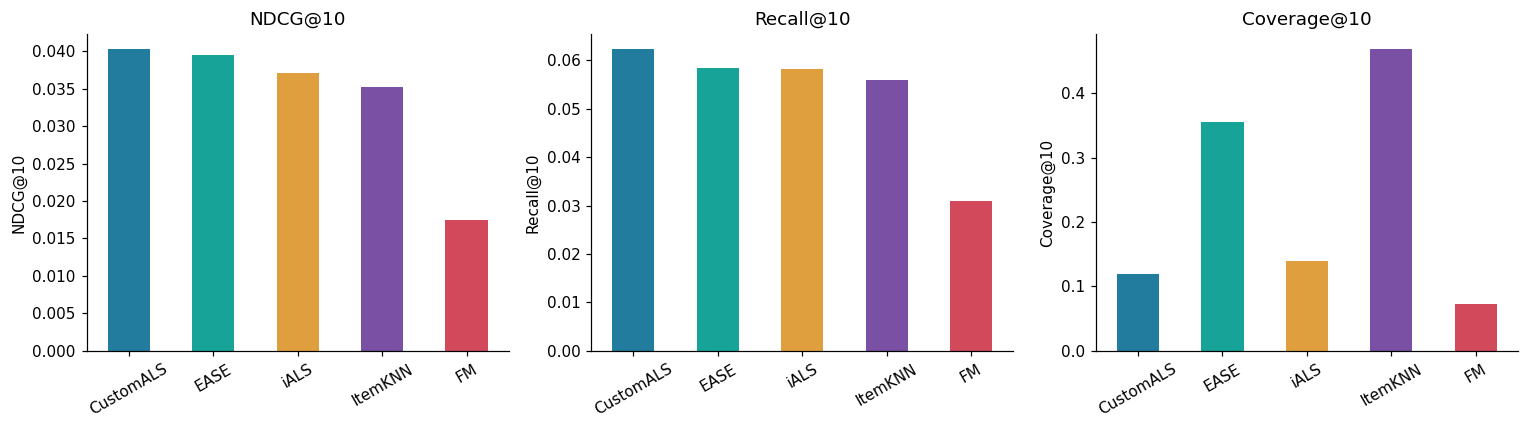

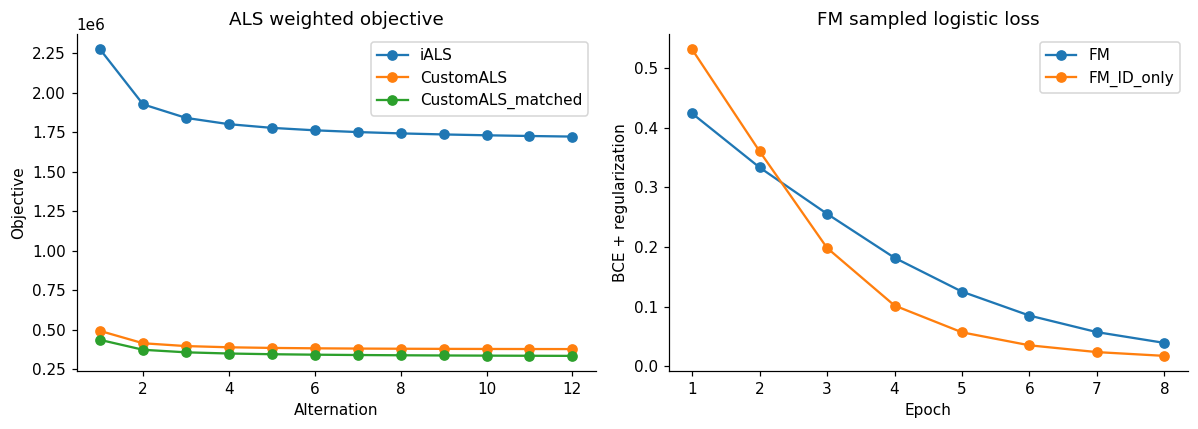

In [8]:
fig, axes=plt.subplots(1,3,figsize=(14,4))
for ax,metric in zip(axes,['NDCG@10','Recall@10','Coverage@10']):
    main_results.set_index('model')[metric].plot.bar(ax=ax,color=['#227c9d','#17a398','#e09f3e','#7950a3','#d1495b'],rot=30)
    ax.set(title=metric,ylabel=metric); ax.set_xlabel('')
plt.tight_layout(); fig.savefig('results/comparison.png'); plt.show()
fig, axes=plt.subplots(1,2,figsize=(11,4))
for name,values in curves.items():
    ax=axes[1] if name.startswith('FM') else axes[0]
    ax.plot(np.arange(1,len(values)+1),values,marker='o',label=name)
axes[0].set(title='ALS weighted objective',xlabel='Alternation',ylabel='Objective')
axes[1].set(title='FM sampled logistic loss',xlabel='Epoch',ylabel='BCE + regularization')
for ax in axes: ax.legend()
plt.tight_layout(); fig.savefig('results/learning_curves.png'); plt.show()
# These losses have different scales/targets; compare convergence, not absolute magnitude.

### Метаданные и авторский таргет: парные сравнения
Для каждого сравнения переиспользуем **одних и тех же test users** и берём разность
пользовательских метрик. Парный bootstrap, 2000 перевыборок с seed=42,
percentile 95% CI. Интервал отражает неопределённость по пользователям этого среза,
а не по seed обучения или новым датасетам; коррекции на множественные проверки нет.

In [9]:
display(comparisons)
target=np.load('results/custom_target.npy')
print('Custom target quantiles:', dict(zip(['min','q25','median','q75','max'],np.quantile(target,[0,.25,.5,.75,1]))))
print('Binary target differs from custom:', bool(np.any(np.abs(target-(test_protocol.events.rating.to_numpy()>=4))>1e-8)))
# Show a deterministic evaluated user with several future relevant items.
example_u=sorted(test_protocol.users,key=lambda u:(-len(test_protocol.truth[u]),int(u)))[0]
example_pos=int(np.flatnonzero(test_protocol.users==example_u)[0])
example=[]
for name in main_names:
    for rank,i in enumerate(recommendations[name][example_pos],1):
        asin=test_protocol.item_ids[i]
        title=metadata.loc[asin,'title'] if asin in metadata.index else ''
        example.append({'model':name,'rank':rank,'ASIN':asin,'title':title or '(title missing)',
                        'relevant_in_test':i in test_protocol.truth[example_u]})
display(pd.DataFrame(example))
# Pseudonymous user ID omitted from the public illustrative output.
pd.DataFrame(example).to_csv('results/example_top10.csv',index=False)

,left,right,metric,delta,ci_low,ci_high
0,FM,FM_ID_only,NDCG@10,0.003797,0.000178,0.007402
1,FM,FM_ID_only,Recall@10,0.008319,0.002172,0.014511
2,CustomALS,iALS,NDCG@10,0.003232,0.000417,0.005861
3,CustomALS,iALS,Recall@10,0.004101,-0.001308,0.009215
4,CustomALS_matched,iALS,NDCG@10,0.002351,-0.000478,0.005103
5,CustomALS_matched,iALS,Recall@10,0.002568,-0.003073,0.007557


Custom target quantiles: {'min': np.float64(0.0), 'q25': np.float64(0.14957926198466862), 'median': np.float64(0.36432838084146124), 'q75': np.float64(0.4468685895378919), 'max': np.float64(0.9652344811826975)}
Binary target differs from custom: True


,model,rank,ASIN,title,relevant_in_test
0,ItemKNN,1,B000FQ2D5E,(title missing),False
1,ItemKNN,2,B000ZK9QCS,(title missing),False
2,ItemKNN,3,B000FQBF1M,(title missing),False
3,ItemKNN,4,B002I0F5M8,(title missing),False
4,ItemKNN,5,B001E8VB6O,(title missing),False
5,ItemKNN,6,B002NN7AKU,(title missing),False
6,ItemKNN,7,B002CZ38KA,(title missing),False
7,ItemKNN,8,B001IVXI7C,(title missing),False
8,ItemKNN,9,B000JLIXIG,(title missing),False
9,ItemKNN,10,B000HKP88C,(title missing),False


## 6. Выводы по реально полученным результатам
Числа ниже вычисляются из итоговой таблицы и парных сравнений, а не подставляются вручную.

In [10]:
best=main_results.iloc[0]
lookup=results.set_index('model')
lines=[f"**Лидер по заранее выбранной NDCG@10 — {best['model']}**: "
       f"NDCG@10={best['NDCG@10']:.5f}, Recall@10={best['Recall@10']:.5f}. "
       f"Выбранные на validation параметры: `{best['params']}`."]
recall_best=main_results.sort_values('Recall@10',ascending=False).iloc[0]
lines.append(f"Максимальный Recall@10 у {recall_best['model']} ({recall_best['Recall@10']:.5f}). "
             'Эти метрики отвечают на разные вопросы: порядок первых позиций и полнота найденных предпочтений.')
for left,right,label in [('FM','FM_ID_only','Влияние причинных метапризнаков FM'),
                         ('CustomALS','iALS','Custom ALS против базового iALS после отдельного подбора'),
                         ('CustomALS_matched','iALS','Эффект авторского таргета при одинаковых параметрах ALS')]:
    row=comparisons[(comparisons.left==left)&(comparisons.right==right)&(comparisons.metric=='NDCG@10')].iloc[0]
    supported = row.ci_low>0 or row.ci_high<0
    direction='выше' if row.delta>0 else 'ниже'
    verdict=('интервал не включает ноль' if supported else 'интервал включает ноль, уверенного эффекта здесь нет')
    lines.append(f"**{label}:** NDCG@10 {direction} на {abs(row.delta):.5f}; "
                 f"95% CI разности [{row.ci_low:.5f}, {row.ci_high:.5f}], {verdict}.")
fast=main_results.sort_values('fit_seconds').iloc[0]
lines.append(f"Минимальное время финального обучения — {fast['model']} ({fast.fit_seconds:.1f} с). "
             'Это измерение на данном компьютере, а не универсальная оценка скорости.')
conclusions='\n\n'.join(lines)
display(Markdown(conclusions))
Path('results/conclusions.md').write_text(conclusions+'\n')

**Лидер по заранее выбранной NDCG@10 — CustomALS**: NDCG@10=0.04028, Recall@10=0.06232. Выбранные на validation параметры: `{"alpha": 20.0, "factors": 64, "half_life_days": 180, "iterations": 12, "regularization": 10.0, "seed": 42}`.

Максимальный Recall@10 у CustomALS (0.06232). Эти метрики отвечают на разные вопросы: порядок первых позиций и полнота найденных предпочтений.

**Влияние причинных метапризнаков FM:** NDCG@10 выше на 0.00380; 95% CI разности [0.00018, 0.00740], интервал не включает ноль.

**Custom ALS против базового iALS после отдельного подбора:** NDCG@10 выше на 0.00323; 95% CI разности [0.00042, 0.00586], интервал не включает ноль.

**Эффект авторского таргета при одинаковых параметрах ALS:** NDCG@10 выше на 0.00235; 95% CI разности [-0.00048, 0.00510], интервал включает ноль, уверенного эффекта здесь нет.

Минимальное время финального обучения — ItemKNN (0.2 с). Это измерение на данном компьютере, а не универсальная оценка скорости.

966

### Интерпретация настроек и компромиссов

На validation у ItemKNN `k=50, shrinkage=20` даёт NDCG@10=0,02788 против 0,01760
при том же k без shrinkage. Это согласуется с тем, что малые пересечения редких товаров
дают шумное cosine-сходство. Увеличение k до 150 при shrinkage=20 не улучшило основную метрику.
У EASE лучшая проверенная λ=50; при λ=800 NDCG падает с 0,03454 до 0,02849.
У iALS 64 фактора лучше 32 в обеих проверенных регуляризациях, но разница между λ=1 и λ=10
при 64 факторах мала (0,03311 против 0,03308), поэтому устойчивость выбора λ не установлена.
В проверенной сетке CustomALS выигрывает с 64 факторами, λ=10 и h=180 дней;
более длинный half-life 730 дней при этих параметрах даёт validation NDCG 0,03617 против 0,03819.
Выбранная FM: 32 фактора, learning rate 0,01, L2=0,0001, 8 эпох.

На test custom ALS получил **наибольшую наблюдённую** NDCG@10; это не утверждение
статистически подтверждённого превосходства над близким EASE.
Прирост NDCG относительно базового iALS после отдельного подбора составляет около 8,7%.
При одинаковых параметрах ALS прирост меньше, а доверительный интервал включает ноль:
поэтому нельзя приписать весь выигрыш только формуле таргета.

FM с метапризнаками превосходит собственную ID-only абляцию по NDCG и Recall,
но остаётся слабее остальных четырёх методов в данном бюджете обучения.
Её охват каталога — 7,2% против 26,2% у ID-only: улучшение релевантности сопровождается
сильной концентрацией рекомендаций. Признаки исторической популярности могут объяснять
эту концентрацию, но для причинного вывода нужны дополнительные абляции полей.
ItemKNN охватывает 46,8% каталога, EASE — 35,6%, iALS — 14,0%, custom ALS — 11,9%:
максимальная персональная точность здесь не означает максимальное разнообразие каталога.


### Ограничения и возможное продолжение
- У отзывов есть selection/exposure bias, неотзывчивые пользователи и просмотренные без
оценки товары неизвестны. Это качество прогноза высоких отзывов, не доказанное улучшение продаж.
- Готовый 5-core выбран авторами по всему горизонту, поэтому результат не переносится
на полный поток редких пользователей. Временная оценка дополнительно исключает cold start;
числа исключений приведены в аудите.
- Каталог основан на первом отзыве, не реальной дате выпуска/доступности. Нет остатков и региона.
Метаданные загружены историческим снимком, их версии не восстановлены; поэтому FM использует
только причинные поведенческие метапризнаки, а не характеристики жанра или текста.
- Validation длится год, test — около полугода. Внутри окна профиль фиксирован;
другой горизонт и rolling evaluation могут изменить ранжирование методов.
- Небольшая сетка, один обучающий seed, фиксированные 12 итераций ALS и 8 эпох FM
ограничивают вывод «лучший метод» рамками проверенных настроек. Абляции условны на выбранные
настройки основных методов; отрицательный эффект не доказывает бесполезность метаданных вообще.
- Confidence у iALS повышен для всех наблюдаемых оценок, включая отрицательные предпочтения;
нельзя напрямую переносить результат на click-only implicit данные.
- EASE требует квадратичной памяти; FM использует сэмплированные отрицательные пары,
их вероятность не является калиброванной вероятностью будущей покупки.
- Bootstrap не учитывает временную зависимость пользователей и вариативность обучения.
Следующий эксперимент — несколько временных срезов и seeds, более широкая сетка,
отдельная cold-start модель и, если доступны, версионированные признаки каталога.

### Проверка корректности и ссылки
`python -m pytest -q` проверяет нормальные уравнения и убывание objective ALS,
решение EASE относительно независимой constrained ridge-задачи, cosine/top-k KNN,
FM относительно явного суммирования всех пар и точного ускоренного скоринга,
причинность и обработку совпадающих timestamps, новый таргет, ручной расчёт метрик,
исключение cold/seen объектов и детерминированность ties.

Первичные источники формул:
[Hu, Koren, Volinsky, 2008: implicit ALS](https://yifanhu.net/PUB/cf.pdf),
[Steck, 2019: EASE](https://arxiv.org/abs/1905.03375),
[Rendle, 2010: Factorization Machines](https://doi.org/10.1109/ICDM.2010.127).
Датасет: [McAuley et al., 2015 / Amazon product data](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html).
Оригинальная формула custom target описана выше и реализована непосредственно в проекте.